In [2]:
import boto3
from botocore.client import Config

# Bucket de destino 
BUCKET = "datalake-bronze"

s3 = boto3.client(
    "s3",
    endpoint_url="http://minio:9000",
    aws_access_key_id="minioadmin",
    aws_secret_access_key="minioadmin",
    config=Config(signature_version="s3v4"),
    region_name="us-east-1",
)

if BUCKET not in [b["Name"] for b in s3.list_buckets()["Buckets"]]:
    s3.create_bucket(Bucket=BUCKET)
print("Buckets:", [b["Name"] for b in s3.list_buckets()["Buckets"]])

Buckets: ['datalake-bronze', 'meu-bucket', 'meu-novo-bucket']


In [3]:
import time, os, json
from pyspark.sql import SparkSession

# =====================================================
# Sessão Spark
# =====================================================
spark = (
    SparkSession.builder
    .appName("Benchmark-Formats")
    .master("local[*]")
    .config("spark.executor.memory", "1g")
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem")
    .config("spark.hadoop.fs.s3a.path.style.access", "true")
    .config("spark.hadoop.fs.s3a.connection.ssl.enabled", "true")
    .config("spark.hadoop.fs.s3a.endpoint", "http://minio:9000")
    .config("spark.hadoop.fs.s3a.access.key", "minioadmin")
    .config("spark.hadoop.fs.s3a.secret.key", "minioadmin")
    .config("spark.hadoop.fs.s3a.committer.name", "directory")
    .getOrCreate()
)
sc = spark.sparkContext
sc.setLogLevel("ERROR")

# =====================================================
# Dataset base (local CSV)
# =====================================================
schema = "raceId INT, driverId INT, lap INT, position INT, time STRING, milliseconds INT"
df = spark.read.csv("/home/jovyan/data/lap_times.csv", header=True, schema=schema)
print("Linhas carregadas:", df.count())

# =====================================================
# Funções auxiliares
# =====================================================
def medir_tempo(op, label):
    inicio = time.time()
    result = op()
    fim = time.time()
    print(f"{label}: {fim - inicio:.2f}s")
    return fim - inicio, result

def medir_leitura(fmt, path):
    inicio = time.time()
    if fmt == "csv":
        df = spark.read.option("header", True).csv(path)
    elif fmt == "json":
        df = spark.read.json(path)
    elif fmt == "parquet":
        df = spark.read.parquet(path)
    elif fmt == "avro":
        df = spark.read.format("avro").option("ignoreExtension", "true").load(path)
    elif fmt == "orc":
        df = spark.read.orc(path)
    linhas = df.count()
    fim = time.time()
    return fim - inicio, linhas

# =====================================================
# Escrita em diferentes formatos no MinIO
# =====================================================
base = "s3a://datalake-bronze/lap_times_"
formats = ["csv", "json", "parquet", "avro", "orc"]
tempos_escrita = {}
for fmt in formats:
    path = base + fmt
    print(f"Gravando {fmt.upper()} -> {path}")
    inicio = time.time()
    if fmt == "csv":
        df.write.mode("overwrite").option("header", True).csv(path)
    elif fmt == "json":
        df.write.mode("overwrite").json(path)
    elif fmt == "parquet":
        df.write.mode("overwrite").parquet(path)
    elif fmt == "avro":
        df.write.mode("overwrite").format("avro").save(path)
    elif fmt == "orc":
        df.write.mode("overwrite").orc(path)
    fim = time.time()
    tempos_escrita[fmt] = round(fim - inicio, 2)
    print(f"→ Tempo de escrita {fmt.upper()}: {tempos_escrita[fmt]}s")

# =====================================================
# Verifica tamanhos com mc (precisa alias 'local')
# =====================================================
!mc alias set local http://minio:9000 minioadmin minioadmin >/dev/null
tamanhos = {}
for fmt in formats:
    info = os.popen(f"mc du --json local/datalake-bronze/lap_times_{fmt}/").read()
    try:
        tamanho = float(json.loads(info)["size"]) / (1024 * 1024)
    except:
        tamanho = 0
    tamanhos[fmt] = round(tamanho, 2)

# =====================================================
# Leitura e benchmark
# =====================================================
tempos_leitura = {}
linhas_lidas = {}
for fmt in formats:
    path = base + fmt
    try:
        tempo, linhas = medir_leitura(fmt, path)
        tempos_leitura[fmt] = round(tempo, 2)
        linhas_lidas[fmt] = linhas
        print(f"{fmt.upper()}: {linhas} linhas em {tempo:.2f}s")
    except Exception as e:
        tempos_leitura[fmt] = None
        linhas_lidas[fmt] = 0
        print(f"Erro ao ler {fmt}: {e}")

# =====================================================
# Resultado consolidado
# =====================================================
print("\n=== RESULTADO FINAL ===")
print(f"{'Formato':<10} {'Tamanho (MB)':>12} {'Escrita (s)':>12} {'Leitura (s)':>12} {'Linhas':>10}")
for fmt in formats:
    print(f"{fmt.upper():<10} {tamanhos[fmt]:>12.2f} {tempos_escrita[fmt]:>12.2f} {tempos_leitura[fmt] or 0:>12.2f} {linhas_lidas[fmt]:>10}")


Linhas carregadas: 551742
Gravando CSV -> s3a://datalake-bronze/lap_times_csv


→ Tempo de escrita CSV: 2.24s
Gravando JSON -> s3a://datalake-bronze/lap_times_json


→ Tempo de escrita JSON: 1.42s
Gravando PARQUET -> s3a://datalake-bronze/lap_times_parquet


→ Tempo de escrita PARQUET: 2.62s
Gravando AVRO -> s3a://datalake-bronze/lap_times_avro


→ Tempo de escrita AVRO: 0.99s
Gravando ORC -> s3a://datalake-bronze/lap_times_orc


→ Tempo de escrita ORC: 1.35s


CSV: 551742 linhas em 1.58s


JSON: 551742 linhas em 1.66s
PARQUET: 551742 linhas em 0.62s


AVRO: 551742 linhas em 1.49s
ORC: 551742 linhas em 0.36s

=== RESULTADO FINAL ===
Formato    Tamanho (MB)  Escrita (s)  Leitura (s)     Linhas
CSV               14.65         2.24         1.58     551742
JSON              47.80         1.42         1.66     551742
PARQUET            4.37         2.62         0.62     551742
AVRO               7.34         0.99         1.49     551742
ORC                4.19         1.35         0.36     551742


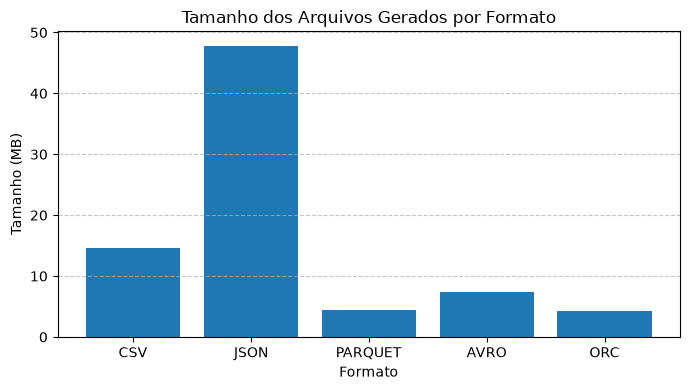

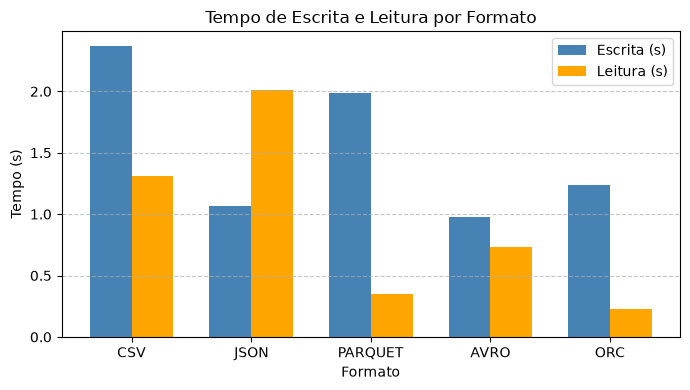

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# Dados obtidos no benchmark exemplo
data = {
    "Formato": ["CSV", "JSON", "PARQUET", "AVRO", "ORC"],
    "Tamanho_MB": [14.65, 47.80, 4.37, 7.34, 4.19],
    "Escrita_s": [2.37, 1.07, 1.99, 0.98, 1.24],
    "Leitura_s": [1.31, 2.01, 0.35, 0.73, 0.23]
}

df = pd.DataFrame(data)

# --- Gráfico 1: Tamanho ---
plt.figure(figsize=(7,4))
plt.bar(df["Formato"], df["Tamanho_MB"])
plt.title("Tamanho dos Arquivos Gerados por Formato")
plt.ylabel("Tamanho (MB)")
plt.xlabel("Formato")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# --- Gráfico 2: Tempo de Escrita vs Leitura ---
plt.figure(figsize=(7,4))
bar_width = 0.35
x = range(len(df))

plt.bar(x, df["Escrita_s"], width=bar_width, label="Escrita (s)", color="steelblue")
plt.bar([p + bar_width for p in x], df["Leitura_s"], width=bar_width, label="Leitura (s)", color="orange")

plt.xticks([p + bar_width/2 for p in x], df["Formato"])
plt.title("Tempo de Escrita e Leitura por Formato")
plt.ylabel("Tempo (s)")
plt.xlabel("Formato")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
